In [5]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error

In [3]:
#1.LOAD OF DATASET

In [6]:
#Load diabetes dataset as a pandas DataFrame
diabetes = load_diabetes(as_frame=True)
df=diabetes.frame
print("---Step 1:Dataset Loaded---")
print(f"Dataset Shape:{df.shape}\n")

---Step 1:Dataset Loaded---
Dataset Shape:(442, 11)



In [ ]:
#2. PERFORM EDA

In [7]:
print("--- Step 2: Exploratory Data Analysis ---")
print("Missing values per column:")
print(df.isnull().sum())  # Check for missing data
print("\nStatistical Summary:")
print(df.describe().round(4))

--- Step 2: Exploratory Data Analysis ---
Missing values per column:
age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64

Statistical Summary:
            age       sex       bmi        bp        s1        s2        s3  \
count  442.0000  442.0000  442.0000  442.0000  442.0000  442.0000  442.0000   
mean    -0.0000    0.0000   -0.0000   -0.0000   -0.0000    0.0000   -0.0000   
std      0.0476    0.0476    0.0476    0.0476    0.0476    0.0476    0.0476   
min     -0.1072   -0.0446   -0.0903   -0.1124   -0.1268   -0.1156   -0.1023   
25%     -0.0373   -0.0446   -0.0342   -0.0367   -0.0342   -0.0304   -0.0351   
50%      0.0054   -0.0446   -0.0073   -0.0057   -0.0043   -0.0038   -0.0066   
75%      0.0381    0.0507    0.0312    0.0356    0.0284    0.0298    0.0293   
max      0.1107    0.0507    0.1706    0.1320    0.1539    0.1988    0.1812   

             s4        s5        s6    target  
coun

In [ ]:
# 3. CHECK FEATURE CORRELATIONS


--- Step 3: Checking Feature Correlations ---
Correlation of features with target variable (Disease Progression):
target    1.000000
bmi       0.586450
s5        0.565883
bp        0.441482
s4        0.430453
s6        0.382483
s1        0.212022
age       0.187889
s2        0.174054
sex       0.043062
s3       -0.394789
Name: target, dtype: float64


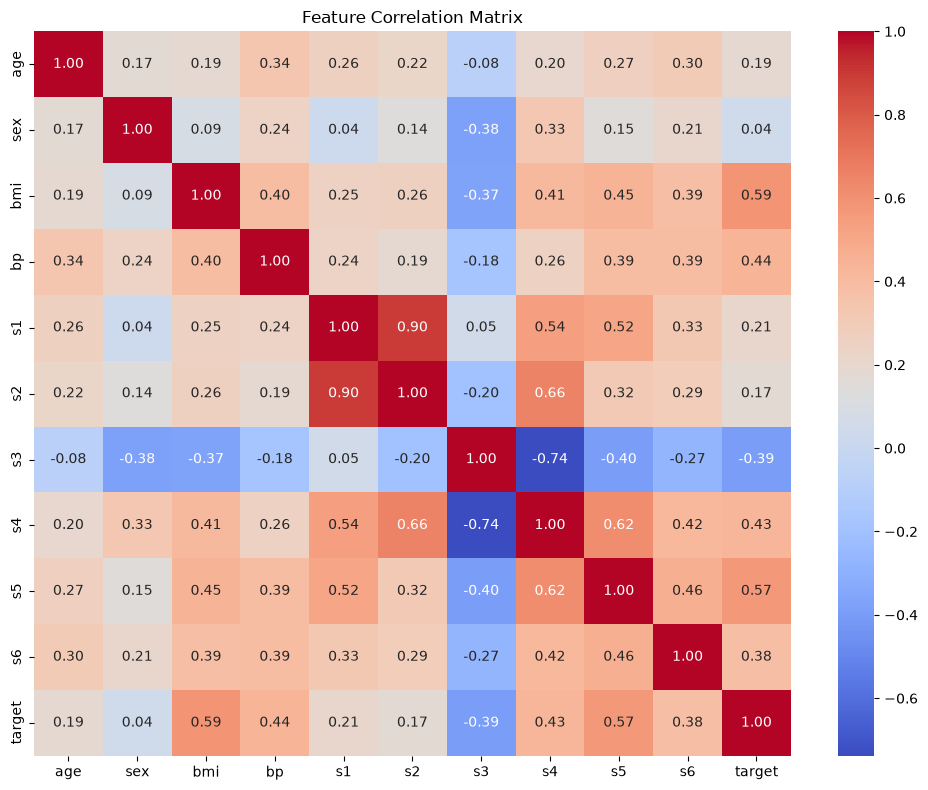

In [8]:
print("\n--- Step 3: Checking Feature Correlations ---")
# Compute correlation matrix
correlation_matrix = df.corr()
# Get correlations specifically with the target variable
target_corr = correlation_matrix['target'].sort_values(ascending=False)
print("Correlation of features with target variable (Disease Progression):")
print(target_corr)

# Optional Visualisation for EDA & Correlation
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

In [ ]:
# 4. TRAIN A LINEAR REGRESSION MODEL

In [13]:
X = df.drop(columns=['target'])
y = df['target']

# Split into training set (80%) and testing set (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialise and train the Linear Regression Model
model = LinearRegression()
model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = model.predict(X_test)
print("\n--- Step 4: Model Training Complete ---")


--- Step 4: Model Training Complete ---


In [14]:
# 5. EVALUATE USING R², MAE, RMSE

In [15]:
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("\n--- Step 5: Model Evaluation Metrics ---")
print(f"R² (Coefficient of Determination) : {r2:.4f}")
print(f"MAE (Mean Absolute Error)         : {mae:.4f}")
print(f"RMSE (Root Mean Squared Error)    : {rmse:.4f}")


--- Step 5: Model Evaluation Metrics ---
R² (Coefficient of Determination) : 0.4526
MAE (Mean Absolute Error)         : 42.7941
RMSE (Root Mean Squared Error)    : 53.8534


In [16]:
# 6. IDENTIFY THE MOST INFLUENTIAL FEATURES

In [17]:
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_
})
# Sort by absolute value to find magnitude of influence
coefficients['Abs_Coefficient'] = coefficients['Coefficient'].abs()
coefficients = coefficients.sort_values(by='Abs_Coefficient', ascending=False).drop(columns=['Abs_Coefficient'])

print("\n--- Step 6: Feature Importance (Model Coefficients) ---")
print(coefficients.to_string(index=False))


--- Step 6: Feature Importance (Model Coefficients) ---
Feature  Coefficient
     s1  -931.488846
     s5   736.198859
    bmi   542.428759
     s2   518.062277
     bp   347.703844
     s4   275.317902
    sex  -241.964362
     s3   163.419983
     s6    48.670657
    age    37.904021


In [18]:
# 7. COMPARE ACTUAL VS PREDICTED VALUES


--- Step 7: Sample Comparison (Actual vs Predicted) ---
   Actual Value  Predicted Value  Residual (Error)
0         219.0           139.55             79.45
1          70.0           179.52           -109.52
2         202.0           134.04             67.96
3         230.0           291.42            -61.42
4         111.0           123.79            -12.79
5          84.0            92.17             -8.17
6         242.0           258.23            -16.23
7         272.0           181.34             90.66
8          94.0            90.22              3.78
9          96.0           108.63            -12.63


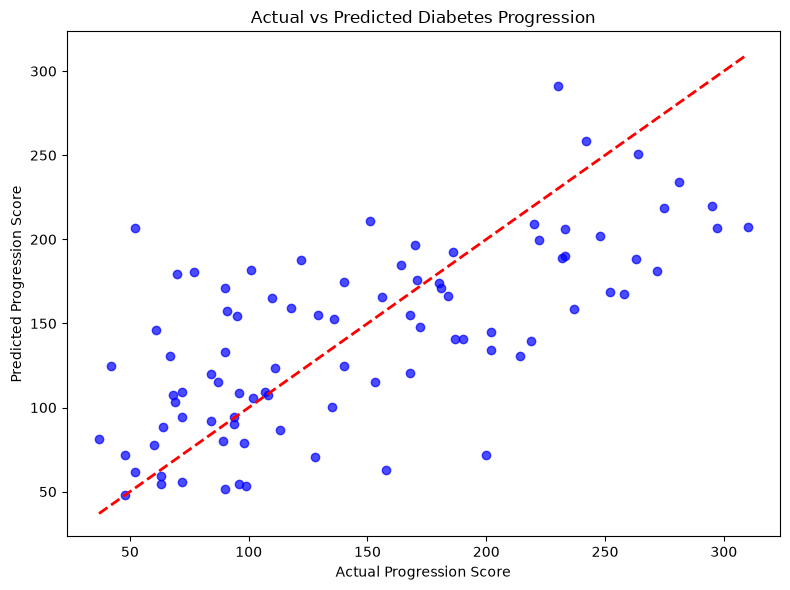

In [19]:
print("\n--- Step 7: Sample Comparison (Actual vs Predicted) ---")
comparison_df = pd.DataFrame({
    'Actual Value': y_test.values,
    'Predicted Value': y_pred.round(2),
    'Residual (Error)': (y_test.values - y_pred).round(2)
})
print(comparison_df.head(10)) # Show first 10 sample predictions

# Optional Visualization for Actual vs Predicted
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.7, color='b')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Actual Progression Score')
plt.ylabel('Predicted Progression Score')
plt.title('Actual vs Predicted Diabetes Progression')
plt.tight_layout()
plt.show()